# Question 1

## Problem Statement

A counter-flow heat exchanger consists of two co-axial pipes, the inner pipe carrying hot fluid, the outer one cold fluid, the flow velocities being oppositely oriented in the pipes. Heat transfer between the two fluids across the tube wall is modelled by the differential equations:

$$
m_h C_h \frac{dT_h}{dx} + H_i P_i (T_h - T_c) = 0, \quad 0 \le x \le L
$$
$$
m_c C_c \frac{dT_c}{dx} + H_o P_o (T_c - T_o) + H_i P_i (T_c - T_h) = 0
$$

With boundary conditions $T_h(0) = T_{ho}$ and $T_c(L) = T_{co}$.

Here $T_h, m_h, C_h$ are the temperature, mass flowrate and specific heat of the hot fluid; $T_c, m_c, C_c$ are the corresponding quantities for the cold fluid; $H_i, H_o$ are the convective heat transfer coefficients at the inner and outer pipe surfaces; $P_i, P_o$ are the perimeters of the inner and outer pipes; and $T_o$ is the ambient outer temperature.

Write a program to solve these equations for a given set of parameters: $L, m_h, C_h, m_c, C_c,$ $H_i, H_o, P_i, P_o, T_o, T_{ho}$ and $T_{co}$.

\newpage

## Analysis and Inputs

- Dividing each equation by its heat capacity rate, the system is rewritten as a first-order system with constant coefficients:
  $$
  \frac{dT_h}{dx} = -a\,(T_h - T_c), \qquad
  \frac{dT_c}{dx} = b\,(T_h - T_c) - c\,(T_c - T_o)
  $$
  where
  $$
  a = \frac{H_i P_i}{m_h C_h}, \qquad b = \frac{H_i P_i}{m_c C_c}, \qquad c = \frac{H_o P_o}{m_c C_c}
  $$
- The two boundary conditions are specified at **different ends** of the pipe ($T_h$ at $x = 0$, $T_c$ at $x = L$), so this is a **split boundary value problem**: at $x = 0$ only $T_h$ is known and at $x = L$ only $T_c$ is known. It cannot be marched directly as an IVP with RK4, since $T_c(0)$ is missing.
- We use the **shooting technique**, which converts the split BVP into a sequence of IVPs: guess the missing initial value $s = T_c(0)$, integrate the IVP $[T_h(0), T_c(0)] = [T_{ho}, s]$ from $x = 0$ to $x = L$ with RK4, and measure how badly the far boundary condition is missed:
  $$
  r(s) = T_c(L; s) - T_{co}
  $$
  The correct $s$ is the root of $r(s) = 0$, which is found with the secant method (no analytical derivative of $r$ is available, as $r$ is the output of a numerical integration).
- Since the ODEs are linear, $r(s)$ is a linear function of $s$, so the secant method is expected to converge in essentially one step.
- To validate the result, the system $\mathbf{T}' = A\mathbf{T} + \mathbf{q}$ has the exact solution
  $$
  \mathbf{T}(x) = e^{Ax}\left(\mathbf{T}(0) + A^{-1}\mathbf{q}\right) - A^{-1}\mathbf{q}, \quad
  A = \begin{bmatrix} -a & a \\ b & -b-c \end{bmatrix}, \;
  \mathbf{q} = \begin{bmatrix} 0 \\ c\,T_o \end{bmatrix}
  $$
  which is compared against the shooting solution.
- We fetch from the user the set of parameters and the number of RK4 steps, given an input file as follows (SI units):

```yaml
L: 5
m_h: 0.1
C_h: 4180
m_c: 0.2
C_c: 4180
H_i: 500
H_o: 50
P_i: 0.1
P_o: 0.2
T_o: 300
T_ho: 360
T_co: 310
n_steps: 50
```

In [1]:
fprintf("--- INPUT ---\n");
[~, p] = readvars("input.txt", "TextType", "string");
p = double(p);

L = p(1); m_h = p(2); C_h = p(3); m_c = p(4); C_c = p(5);
H_i = p(6); H_o = p(7); P_i = p(8); P_o = p(9); T_o = p(10);
T_ho = p(11); T_co = p(12); n_steps = p(13);

a = H_i * P_i / (m_h * C_h);
b = H_i * P_i / (m_c * C_c);
c = H_o * P_o / (m_c * C_c);

% state T = [T_h; T_c]
f = @(x, T) [-a * (T(1) - T(2)); ...
              b * (T(1) - T(2)) - c * (T(2) - T_o)];

disp(table(L, n_steps, a, b, c, T_ho, T_co, T_o));

--- INPUT ---
    L    n_steps       a          b           c        T_ho    T_co    T_o
    _    _______    _______    ________    ________    ____    ____    ___

    5      50       0.11962    0.059809    0.011962    360     310     300



\newpage

## 1. Initial Value Problem Solver (RK4)

- For a trial value $s$, the IVP is marched from $x = 0$ to $x = L$ with step $h = L / n$ using the fourth-order Runge-Kutta formula, applied to the vector $\mathbf{T} = [T_h, T_c]^T$:
$$
\mathbf{T}_{n+1} = \mathbf{T}_n + \frac{h}{6}(\mathbf{k}_1 + 2\mathbf{k}_2 + 2\mathbf{k}_3 + \mathbf{k}_4)
$$
$$
\mathbf{k}_1 = \mathbf{f}(x_n, \mathbf{T}_n), \quad
\mathbf{k}_2 = \mathbf{f}\left(x_n + \tfrac{h}{2}, \mathbf{T}_n + \tfrac{h}{2}\mathbf{k}_1\right), \quad
$$
$$
\mathbf{k}_3 = \mathbf{f}\left(x_n + \tfrac{h}{2}, \mathbf{T}_n + \tfrac{h}{2}\mathbf{k}_2\right), \quad
\mathbf{k}_4 = \mathbf{f}(x_n + h, \mathbf{T}_n + h\mathbf{k}_3)
$$

### Implementation

In [2]:
%%file rk4_system.m
function [x, T] = rk4_system(f, T_0, L, n) %#ok<FNDEF>
    h = L / n;
    x = linspace(0, L, n + 1)';
    T = zeros(n + 1, numel(T_0));
    T(1, :) = T_0(:)';

    for i = 1:n
        T_i = T(i, :)';

        k1 = f(x(i), T_i);
        k2 = f(x(i) + h/2, T_i + h/2 * k1);
        k3 = f(x(i) + h/2, T_i + h/2 * k2);
        k4 = f(x(i) + h, T_i + h * k3);

        T(i + 1, :) = (T_i + h / 6 * (k1 + 2*k2 + 2*k3 + k4))';
    end
end

File rk4_system.m created successfully.

\newpage

## 2. Shooting Method with Secant Root Finding

### Algorithm

- **Step 01.** **START**
- **Step 02.** Inputs:

| Variable | Description |
| -------- | ----------- |
| $\mathbf{f}$ | Right-hand side, $d\mathbf{T}/dx = \mathbf{f}(x, \mathbf{T})$ |
| $L, n$ | Pipe length and number of RK4 steps |
| $T_{ho}, T_{co}$ | Boundary values $T_h(0)$ and $T_c(L)$ |
| $s_0, s_1$ | Two initial guesses for $T_c(0)$ |
| $\epsilon$ | Tolerance on the boundary residual |

- **Step 03.** Define $r(s)$: integrate the IVP with $\mathbf{T}(0) = [T_{ho}, s]^T$ using RK4 and return $T_c(L) - T_{co}$
- **Step 04.** Initialize: $k = 1$
- **Step 05.** Repeat until $|r(s_k)| < \epsilon$:
  - **Step 06.** Compute the next guess:
    $$
    s_{k+1} = s_k - r(s_k)\,\frac{s_k - s_{k-1}}{r(s_k) - r(s_{k-1})}
    $$
  - **Step 07.** Increment $k = k + 1$
- **Step 08.** End repeat {**Step 05**}
- **Step 09.** Integrate once more with $T_c(0) = s_k$ to get the full profile
- **Step 10.** Outputs:

| Variable | Description |
| -------- | ----------- |
| $x^{(0..n)}$ | Positions along the pipe |
| $T_h^{(0..n)}, T_c^{(0..n)}$ | Hot and cold fluid temperature profiles |
| $s$ | Converged value of $T_c(0)$ |

- **Step 11.** **STOP**

\newpage

### Implementation

In [3]:
%%file shooting_secant.m
function [s, converged, guess_history] = ...
    shooting_secant(r, s0, s1, epsilon, k_max) %#ok<FNDEF>

% @parameter r: function handle, residual of the far boundary condition
% @parameter s0, s1: two initial guesses for the unknown initial value
% @parameter epsilon: tolerance on |r(s)|
% @parameter k_max: maximum number of iterations

% @return s: converged value of the unknown initial value
% @return converged: shows if convergence was achieved
% @return guess_history: history of guesses

if nargin < 5; k_max = 100; end
if nargin < 4; epsilon = 1e-8; end

guess_history = zeros(k_max + 2, 1);
guess_history(1:2) = [s0; s1];
r0 = r(s0); r1 = r(s1); k = 2;

while abs(r1) >= epsilon && k < k_max + 2
    s2 = s1 - r1 * (s1 - s0) / (r1 - r0);
    s0 = s1; r0 = r1;
    s1 = s2; r1 = r(s1);
    k = k + 1;
    guess_history(k) = s1;
end

s = s1;
converged = abs(r1) < epsilon;
guess_history = guess_history(1:k);

end

File shooting_secant.m created successfully.

In [4]:
%%file shoot_residual.m
function r = shoot_residual(f, T_ho, s, L, n, T_co) %#ok<FNDEF>
    % integrate the IVP with T_c(0) = s and return T_c(L) - T_co
    [~, T] = rk4_system(f, [T_ho; s], L, n);
    r = T(end, 2) - T_co;
end

File shoot_residual.m created successfully.

In [ ]:
fprintf("--- OUTPUT ---\n");
residual = @(s) shoot_residual(f, T_ho, s, L, n_steps, T_co);

[T_c0, converged, history] = shooting_secant(residual, T_co, T_co + 10);
[x, T] = rk4_system(f, [T_ho; T_c0], L, n_steps);

fprintf("\nShooting: converged = %d after %d guesses\n", ... 
    converged, numel(history));
disp(table(history, arrayfun(residual, history), ...
    VariableNames={'T_c0_guess', 'residual'}));

fprintf("Converged T_c(0) = %.6f, T_c(L) = %.6f (target %.2f)\n", ...
    T_c0, T(end, 2), T_co);

n_blocks = 5; m = round(n_steps / n_blocks); h = L / n_steps;
T_h_blocks = zeros(m + 1, n_blocks); T_c_blocks = zeros(m + 1, n_blocks);
names = strings(1, n_blocks);
for k = 1:n_blocks
    idx = (k-1)*m + 1 : k*m + 1;
    T_h_blocks(:, k) = T(idx, 1); T_c_blocks(:, k) = T(idx, 2);
    names(k) = matlab.lang.makeValidName(sprintf("x_%g_to_%g", ...
        (k-1)*L/n_blocks, k*L/n_blocks));
end
offsets = compose("+%.2f", (0:m)' * h);

fprintf("\nT_h (K):\n");
disp(array2table(T_h_blocks, VariableNames=names, RowNames=offsets));
fprintf("T_c (K):\n");
disp(array2table(T_c_blocks, VariableNames=names, RowNames=offsets));

--- OUTPUT ---

Shooting: converged = 1 after 3 guesses
    T_c0_guess     residual 
    __________    __________

         310           9.052
         320          16.623
      298.04      2.2737e-13

Converged T_c(0) = 298.043790, T_c(L) = 310.000000 (target 310.00)

T_h (K):
             x_0_to_1    x_1_to_2    x_2_to_3    x_3_to_4    x_4_to_5
             ________    ________    ________    ________    ________

    +0.00        360      353.22      347.54       342.8      338.83 
    +0.10     359.27       352.6      347.03      342.37      338.46 
    +0.20     358.54         352      346.53      341.95      338.11 
    +0.30     357.84      351.41      346.03      341.53      337.76 
    +0.40     357.14      350.83      345.54      341.13      337.42 
    +0.50     356.46      350.25      345.07      340.72      337.09 
    +0.60     355.78      349.69       344.6      340.33      336.76 
    +0.70     355.13      349.14      344.14      339.94      336.43 
    +0.80     354.4

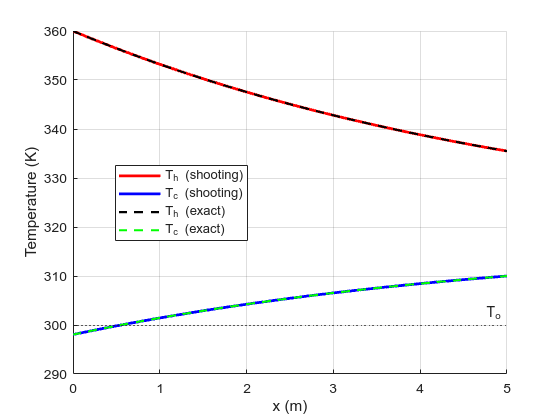

In [ ]:
A = [-a, a; b, -(b + c)]; q = [0; c * T_o];
T_ss = -A \ q;
T_exact = zeros(size(T));
for i = 1:numel(x)
    T_exact(i, :) = (expm(A * x(i)) * ([T_ho; T_c0] - T_ss) + T_ss)';
end

figure; hold on;
plot(x, T(:, 1), "r-", "LineWidth", 2);
plot(x, T(:, 2), "b-", "LineWidth", 2);
plot(x, T_exact(:, 1), "k--", "LineWidth", 1.5);
plot(x, T_exact(:, 2), "g--", "LineWidth", 1.5);
yline(T_o, ":", "T_o");
xlabel("x (m)"); ylabel("Temperature (K)");
legend("T_h (shooting)", "T_c (shooting)", "T_h (exact)", ...
    "T_c (exact)", Location="best");
grid on; hold off;

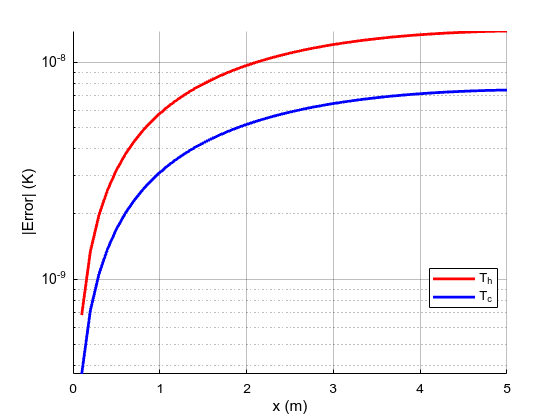

Max abs error: T_h = 1.392e-08, T_c = 7.444e-09


In [ ]:
figure; hold on;
plot(x, abs(T(:, 1) - T_exact(:, 1)), "r-", "LineWidth", 2);
plot(x, abs(T(:, 2) - T_exact(:, 2)), "b-", "LineWidth", 2);
set(gca, 'YScale', 'log', 'Color', 'w', 'XColor', 'k', 'YColor', 'k');
xlabel("x (m)"); ylabel("|Error| (K)");
legend("T_h", "T_c", Location="best", TextColor="k", ...
    Color="w", EdgeColor="k");
grid on; hold off;

fprintf("Max abs error: T_h = %.3e, T_c = %.3e\n", ...
    max(abs(T(:, 1) - T_exact(:, 1))), ...
    max(abs(T(:, 2) - T_exact(:, 2))));

\newpage

## Discussion

- The problem has its boundary conditions at opposite ends of the exchanger, $T_h(0) = T_{ho}$ and $T_c(L) = T_{co}$, so RK4 cannot be used directly. The shooting technique converts the split BVP into repeated IVPs (each one a complete RK4 march from $x = 0$) and reduces the problem to a root-finding problem on the single unknown $T_c(0)$.
- Because the governing equations are linear, the residual $r(s)$ is exactly linear in $s$ (up to RK4 truncation error). The secant method therefore lands on the root after one update, and the second residual evaluated is already at round-off level. This is visible in the iteration table above.
- The shooting solution matches the exact matrix-exponential solution to a very small error (of the order of the RK4 truncation error, $\mathcal{O}(h^4)$), and increasing `n_steps` reduces it further.
- The equations are used exactly as stated in the problem. With these signs, both temperatures are driven toward each other along $x$, and the cold stream also loses heat to the ambient through the $H_o P_o (T_c - T_o)$ term. Note that with the given signs, $T_c$ increases with $x$; if the cold stream is meant to flow in the $-x$ direction, the sign of the cold-stream terms would have to be reversed, which only requires changing the second line of `f`.
- For a strongly stiff set of parameters (very large $a$, $b$ or $c$ relative to $1/L$), shooting can become ill-conditioned and a finite difference (collocation) approach would be preferable.